# Baselines: descriptors and tree ensembles

How far do hand-made descriptors and decision-tree ensembles get on DFT formation energies and band gaps? The answer is the bar that the graph network of the `cgcnn` experiment, and every later method, has to clear.

**Data.** JARVIS-DFT 3D, snapshot 2021.8.18: the one Choudhary & DeCost (*npj Comput. Mater.* **7**, 185, 2021, Table 3) used for CFID, CGCNN and ALIGNN with random 80/10/10 splits. Their test errors (mean absolute error, MAE):

| Target | MAD | CFID | CGCNN | ALIGNN |
|---|---|---|---|---|
| Formation energy (eV/atom) | 0.86 | 0.14 | 0.063 | 0.033 |
| Band gap, OptB88vdW (eV) | 0.99 | 0.30 | 0.20 | 0.14 |

MAD is the mean absolute deviation of the target, the error of always predicting the mean. Their random split is not ours, so the comparison holds to within the split-to-split spread, which is measured here with three random splits.

**Plan.**

1. Data: one record per material.
2. Element data: the Magpie table checked against pymatgen.
3. Descriptors: composition and structure features; the computed density checked against JARVIS.
4. Pipeline check: the published CFID baseline reproduced with the same training and evaluation code.
5. Baselines on three random splits.
6. Learning curves.
7. Parity plots.
8. What the model uses: permutation importance.

| File | Contents |
|---|---|
| `materials_ml_primer/data.py` | JARVIS download, de-duplication, structure arrays |
| `materials_ml_primer/descriptors.py` | Magpie-style composition features, structure features |
| `materials_ml_primer/splits.py` | random train/validation/test split |
| `tests/test_descriptors.py`, `tests/test_data.py`, `tests/test_splits.py` | pytest suites |
| `baselines.ipynb` | this notebook |
| `figures/` | figures written by this notebook |

Run from this folder after installing the package as described in [../../README.md](../../README.md). The data (about 0.5 GB with the CFID descriptors) is downloaded into `../../data/` on the first run.

In [1]:
import subprocess
import sys
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from materials_ml_primer import data, descriptors
from materials_ml_primer.splits import random_split

DATA_DIR = Path("../../data")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10})
TARGETS = {  # short name: (JARVIS key, label, unit)
    "Ef": ("formation_energy_peratom", "formation energy", "eV/atom"),
    "Eg": ("optb88vdw_bandgap", "band gap (OptB88vdW)", "eV"),
}
PAPER = {  # Choudhary & DeCost 2021, Table 3, as printed
    "Ef": {"MAD": "0.86", "CFID": "0.14", "CGCNN": "0.063", "ALIGNN": "0.033"},
    "Eg": {"MAD": "0.99", "CFID": "0.30", "CGCNN": "0.20", "ALIGNN": "0.14"},
}
PAPER_N_TRAIN = 44577  # 80 % of their 55 722 records (their learning-curve study)
SEEDS = (0, 1, 2)
summary = []   # rows of the summary table: (quantity, this run, check, check from)


def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))

## Automated tests

In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", "--color=no",
                    "-p", "no:cacheprovider", "../../tests/test_descriptors.py",
                    "../../tests/test_data.py", "../../tests/test_splits.py"],
                   capture_output=True, text=True)
print(r.stdout[-1500:])

........................................................................ [ 48%]
........................................................................ [ 96%]
.....                                                                    [100%]
149 passed in 0.91s



## 1. Data

Some materials appear more than once under the same JARVIS id. A material with one copy in the training set and another in the test set leaks its answer, so only the first copy is kept. The cell lists the repeated ids and whether their copies agree.

In [3]:
raw = data.download(data.DFT_3D_2021, DATA_DIR)
records, dups = data.deduplicate(raw)
print(f"records: {len(raw)}, unique JARVIS ids kept: {len(records)}")
copies_of = defaultdict(list)
for rec in raw:
    if rec["jid"] in dups:
        copies_of[rec["jid"]].append(rec)
for jid, copies in copies_of.items():
    ref = copies[0]
    differ = sorted({k for c in copies[1:] for k in ref if c[k] != ref[k]})
    detail = "identical" if not differ else "differ in " + ", ".join(differ)
    if "formation_energy_peratom" in differ:
        v = [c["formation_energy_peratom"] for c in copies]
        detail += f" (spread {1000 * (max(v) - min(v)):.1f} meV/atom)"
    print(f"  {jid:13s} {ref['formula']:10s} x{len(copies)}  {detail}")

y = {t: np.array([data.as_float(rec[key]) for rec in records]) for t, (key, _, _) in TARGETS.items()}
print()
for t, (_, label, unit) in TARGETS.items():
    v = y[t]
    mad = mae(v, v.mean())
    print(f"{label}: {np.isfinite(v).sum()} values, mean {v.mean():.3f} {unit}, "
          f"MAD {mad:.3f} {unit} (paper: {PAPER[t]['MAD']})")
    summary.append((f"MAD of {label} ({unit})", f"{mad:.3f}", f"{PAPER[t]['MAD']}", "Choudhary & DeCost 2021"))
print(f"band gaps that are exactly 0: {np.mean(y['Eg'] == 0):.1%}")

records: 55723, unique JARVIS ids kept: 55712
  JVASP-97311   LiBS2O8    x3  differ in formation_energy_peratom (spread 2.9 meV/atom)
  JVASP-96735   Al2O3      x6  identical
  JVASP-100669  Ca2Mg      x2  identical
  JVASP-113961  Li2BN2     x2  identical
  JVASP-116461  Zn3Mo3O8   x3  identical

formation energy: 55712 values, mean -0.832 eV/atom, MAD 0.861 eV/atom (paper: 0.86)
band gap (OptB88vdW): 55712 values, mean 0.688 eV, MAD 0.993 eV (paper: 0.99)
band gaps that are exactly 0: 67.5%


## 2. Element data: calibration

The composition features are statistics of elemental properties. The values are the Magpie table of Ward et al. (*npj Comput. Mater.* **2**, 16028, 2016) as shipped with jarvis-tools. They are compared here with pymatgen, an independent compilation, for every element in the dataset. Two things come out of this:

- The table codes missing values as −9999 instead of leaving them empty. Used as numbers, they would make the mean electronegativity of any argon compound about −2000. `descriptors.magpie_table` turns them into NaN.
- Where the two sources disagree, the cell lists the values.

The ground-state space-group number of each element, also in the table, is not used: it is a label, and its mean or spread over a compound means nothing.

In [4]:
from jarvis.core.specie import chem_data_magpie as RAW_MAGPIE
from pymatgen.core import Element

with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # pymatgen warns about missing noble-gas electronegativities
    elements = sorted({s for rec in records for s in rec["atoms"]["elements"]}, key=lambda s: Element(s).Z)
    print(f"{len(elements)} elements in the dataset, Z = {Element(elements[0]).Z}..{Element(elements[-1]).Z}")
    coded = {k: [s for s in elements if RAW_MAGPIE[s][k] <= -999] for k in RAW_MAGPIE["Fe"]}
    print("raw Magpie values coded as -9999:", {k: v for k, v in coded.items() if v})

    def shells(configuration):
        count = dict.fromkeys("spdf", 0)
        for orb in configuration.split("."):
            if len(orb) >= 3 and orb[1] in "spdf" and orb[0].isdigit():
                count[orb[1]] += int(orb[2:])
        return count

    index, table = descriptors.magpie_table()
    P = descriptors.MAGPIE_PROPERTIES
    checks = {
        "Number = Z": ("Number", lambda e: e.Z),
        "AtomicWeight = atomic mass": ("AtomicWeight", lambda e: float(e.atomic_mass)),
        "Row = period": ("Row", lambda e: e.row),
        "Column = group": ("Column", lambda e: e.group),
        "NsValence": ("NsValence", lambda e: shells(e.electronic_structure)["s"]),
        "NpValence": ("NpValence", lambda e: shells(e.electronic_structure)["p"]),
        "NdValence": ("NdValence", lambda e: shells(e.electronic_structure)["d"]),
        "NfValence": ("NfValence", lambda e: shells(e.electronic_structure)["f"]),
        "Electronegativity (Pauling)": ("Electronegativity", lambda e: e.X),
        "MeltingT (K)": ("MeltingT", lambda e: e.melting_point),
    }
    print(f"\n{'Magpie vs pymatgen':30s} agree  differences (Magpie, pymatgen)")
    for label, (prop, ref) in checks.items():
        agree, diffs = 0, []
        for s in elements:
            a, b = table[index[s], P.index(prop)], ref(Element(s))
            b = np.nan if b is None else float(b)
            if (np.isnan(a) and np.isnan(b)) or (not np.isnan(a + b) and abs(a - b) <= 1e-3 * abs(b)):
                agree += 1
            else:
                diffs.append(f"{s} ({a:g}, {b:g})")
        print(f"{label:30s} {agree:2d}/{len(elements)}  {', '.join(diffs)}")
        if prop in ("Number", "AtomicWeight", "Row", "Column", "NsValence", "NpValence", "NdValence", "NfValence"):
            summary.append((f"element data, {label}", f"{agree}/{len(elements)}", f"{len(elements)}/{len(elements)}", "pymatgen"))

89 elements in the dataset, Z = 1..94
raw Magpie values coded as -9999: {'Electronegativity': ['He', 'Ne', 'Ar'], 'MeltingT': ['He']}

Magpie vs pymatgen             agree  differences (Magpie, pymatgen)
Number = Z                     89/89  
AtomicWeight = atomic mass     89/89  
Row = period                   89/89  
Column = group                 89/89  
NsValence                      89/89  
NpValence                      89/89  
NdValence                      89/89  
NfValence                      89/89  
Electronegativity (Pauling)    85/89  Pm (1.155, 1.13), Eu (1.185, 1.2), Tb (1.21, 1.1), Yb (1.26, 1.1)
MeltingT (K)                   74/89  He (nan, 0.95), C (3823, 3800), Ce (1071, 1068), Pr (1204, 1208), Nd (1294, 1297), Eu (1095, 1099), Dy (1685, 1680), Ho (1747, 1734), Er (1770, 1802), Yb (1092, 1097), Lu (1936, 1925), Th (2023, 2115), Pa (1845, 1841), U (1408, 1405.3), Np (917, 910)


The electronegativities of He, Ne and Ar are missing in both sources, so they agree once the −9999 codes are removed. The remaining differences are all in elements whose values are poorly known: Pauling electronegativities of four lanthanides (by up to 0.16 for Yb), and melting points of lanthanides and actinides, which differ between compilations by a few kelvin and by up to 92 K for thorium. Carbon has no melting point at ambient pressure (it sublimes), and the Magpie table has none for helium. The Magpie values are kept as published.

## 3. Descriptors

- **Composition (136 features)**: number of elements and the L_p norms of the atomic fractions (p = 2, 3, 5, 7, 10); for each of 21 elemental properties the fraction-weighted mean, mean absolute deviation, minimum, maximum, range and mode; and the fractions of valence electrons in s, p, d and f shells.
- **Structure (14 features)**: number of sites, volume per atom, density, the mean, minimum and maximum nearest-neighbor distance, the mean coordination number (neighbors within 1.1 times the nearest-neighbor distance, from the neighbor search of the `crystal_graphs` experiment), and the crystal system as seven 0/1 columns.

The density feature is the cell mass (Magpie atomic weights) over the cell volume. JARVIS stores a density too, rounded to three decimals, but computed with the atomic masses of jarvis-tools, a different table. To check the geometry alone, the density is recomputed from our cell volumes with the JARVIS masses and the JARVIS unit conversion: every difference from the stored value should then be at most 0.0005 g/cm³. The cell also lists where the two mass tables differ and how much that moves the density feature. A few records are an isolated atom or molecule in a large empty box (reference calculations, density below 0.01 g/cm³); they are not crystals, but they are kept so that the dataset stays the one the published numbers refer to.

In [5]:
Xc, Xs = descriptors.jarvis_feature_matrices(records)
names_c = descriptors.composition_feature_names()
names_s = descriptors.structure_feature_names()
X = {"composition": Xc, "composition + structure": np.hstack([Xc, Xs])}
for k, v in X.items():
    print(f"{k:25s} {v.shape[1]} features")

missing = np.isnan(Xc).any(axis=1)
noble = sorted({s for rec, m in zip(records, missing, strict=True) if m for s in rec["atoms"]["elements"]} & {"He", "Ne", "Ar"})
print(f"compounds with a missing elemental value: {missing.sum()} (they contain {', '.join(noble)})")

from jarvis.core.atoms import amu_gm, ang_cm
from jarvis.core.specie import Specie

rho = Xs[:, names_s.index("density")]
rho_jarvis = np.array([rec["density"] for rec in records])
volume = Xs[:, names_s.index("volume_per_atom")] * Xs[:, names_s.index("n_sites")]
mass_jarvis = {s: Specie(s).atomic_mass for s in elements}
cell_mass = np.array([sum(mass_jarvis[s] for s in rec["atoms"]["elements"]) for rec in records])
# JARVIS converts with 1 amu = 1.66054e-24 g (ours: 1.66053906660e-24 g); its factor is used here
diff = np.abs(cell_mass * amu_gm / ang_cm ** 3 / volume - rho_jarvis)
print(f"our cell volumes with JARVIS masses vs stored density: largest |difference| {diff.max():.1e} g/cm3, "
      f"above 0.0005: {(diff > 5e-4 + 1e-9).sum()}")
summary.append(("density (our volumes, JARVIS masses) vs JARVIS, largest |diff| (g/cm³)", f"{diff.max():.1e}",
                "≤ 5e-4", "JARVIS density (3 decimals)"))
mass_magpie = {s: table[index[s], P.index("AtomicWeight")] for s in elements}
print("atomic masses that differ between the tables (Magpie, JARVIS):",
      ", ".join(f"{s} ({mass_magpie[s]:g}, {mass_jarvis[s]:g})" for s in elements
                if abs(mass_magpie[s] - mass_jarvis[s]) > 1e-6))
rho_same_cell = cell_mass * amu_gm / ang_cm ** 3 / volume   # same cell, JARVIS masses and units, unrounded
print(f"density feature (Magpie masses) vs the same cell with JARVIS masses: largest relative difference "
      f"{np.max(np.abs(rho - rho_same_cell) / rho_same_cell):.1e}")
print("records below 0.01 g/cm3 (an isolated atom or molecule in an empty box, not a crystal):",
      ", ".join(f"{rec['jid']} {rec['formula']}" for rec, r in zip(records, rho_jarvis, strict=True) if r < 0.01))
coord = Xs[:, names_s.index("coordination_mean")]
print(f"mean coordination number: median {np.median(coord):.1f}, range {coord.min():.1f}..{coord.max():.1f}")

composition               136 features
composition + structure   150 features
compounds with a missing elemental value: 26 (they contain Ar, He, Ne)


our cell volumes with JARVIS masses vs stored density: largest |difference| 5.0e-04 g/cm3, above 0.0005: 0
atomic masses that differ between the tables (Magpie, JARVIS): Ne (20.1791, 20.1797), Zn (65.38, 65.409), Mo (95.96, 95.94), Yb (173.054, 173.04), Lu (174.967, 174.967), Pa (231.036, 231.036)
density feature (Magpie masses) vs the same cell with JARVIS masses: largest relative difference 4.4e-04
records below 0.01 g/cm3 (an isolated atom or molecule in an empty box, not a crystal): JVASP-7148 Al, JVASP-7379 Cl, JVASP-7406 H, JVASP-7517 Na, JVASP-7544 P, JVASP-7559 S, JVASP-7565 HS, JVASP-7577 Si
mean coordination number: median 4.8, range 1.0..12.0


## 4. Pipeline check: the published CFID baseline

Before our own descriptors are trusted, the training and evaluation code is checked on a case with a known answer. JARVIS distributes the CFID descriptors (Choudhary, DeCost & Tavazza, *Phys. Rev. Mater.* **2**, 083801, 2018; 1557 features of composition, bond lengths, angles and radial distributions) precomputed for this snapshot. The paper fitted them with LightGBM; `HistGradientBoostingRegressor` is scikit-learn's implementation of the same histogram-based gradient boosting. If the test MAE lands near the published 0.14 eV/atom and 0.30 eV, the data handling, split and metric are right.

All gradient-boosting fits stop early on the validation set (the test set is never used for any choice).

In [6]:
def hgb(learning_rate=0.05, max_iter=5000):
    return HistGradientBoostingRegressor(learning_rate=learning_rate, max_iter=max_iter, max_leaf_nodes=63,
                                         early_stopping=True, n_iter_no_change=100, random_state=0)


def fit_predict(model, features, t, split):
    tr, va, te = split
    if isinstance(model, HistGradientBoostingRegressor):
        model.fit(features[tr], y[t][tr], X_val=features[va], y_val=y[t][va])
    else:
        model.fit(features[tr], y[t][tr])
    return model, model.predict(features[te])


splits = {s: random_split(len(records), seed=s) for s in SEEDS}
print("split sizes (train, val, test):", [len(part) for part in splits[0]])

cfid_raw, _ = data.deduplicate(data.download(data.CFID_3D_2021, DATA_DIR))
desc = {rec["jid"]: rec["desc"] for rec in cfid_raw}
X_cfid = np.array([desc[rec["jid"]] for rec in records], dtype=np.float32)
del cfid_raw, desc
print(f"CFID descriptors: {X_cfid.shape}, non-finite values: {(~np.isfinite(X_cfid)).sum()}")

for t, (_, label, unit) in TARGETS.items():
    model, p = fit_predict(hgb(learning_rate=0.1, max_iter=3000), X_cfid, t, splits[0])
    m = mae(p, y[t][splits[0][2]])
    stopped = "early stopping" if model.n_iter_ < 3000 else "iteration limit"
    print(f"{label}: CFID + gradient boosting, test MAE {m:.3f} {unit} (paper {PAPER[t]['CFID']}); "
          f"{model.n_iter_} iterations ({stopped})")
    summary.append((f"CFID + gradient boosting, {label} MAE ({unit})", f"{m:.3f}", f"{PAPER[t]['CFID']}",
                    "Choudhary & DeCost 2021"))

split sizes (train, val, test): [44570, 5571, 5571]


CFID descriptors: (55712, 1557), non-finite values: 0


formation energy: CFID + gradient boosting, test MAE 0.135 eV/atom (paper 0.14); 2123 iterations (early stopping)


band gap (OptB88vdW): CFID + gradient boosting, test MAE 0.288 eV (paper 0.30); 1614 iterations (early stopping)


## 5. Baselines on three random splits

| Model | Features | Details |
|---|---|---|
| mean of the training set | none | the MAD baseline |
| ridge regression | composition + structure | standardized features, missing values replaced by the training median, penalty chosen by internal cross-validation |
| random forest | composition + structure | 300 trees, a third of the features tried at each split |
| gradient boosting | composition | early stopping on the validation set |
| gradient boosting | composition + structure | early stopping on the validation set |

Each model is trained on three random 80/10/10 splits; the table gives the mean and standard deviation of the test MAE. Two thirds of the band gaps are zero (metals), so the band-gap error is also given for the materials with a gap.

In [7]:
MODELS = {
    "mean of training set": None,
    "ridge, comp + struct": ("composition + structure", lambda: make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))),
    "random forest, comp + struct": ("composition + structure", lambda: RandomForestRegressor(
        n_estimators=300, max_features=1 / 3, n_jobs=-1, random_state=0)),
    "gradient boosting, composition": ("composition", hgb),
    "gradient boosting, comp + struct": ("composition + structure", hgb),
}
BEST = "gradient boosting, comp + struct"
results, best_fit, best_pred = {}, {}, {}
for t in TARGETS:
    for name, spec in MODELS.items():
        all_mae, gap_mae = [], []
        for s in SEEDS:
            tr, va, te = splits[s]
            if spec is None:
                p = np.full(len(te), y[t][tr].mean())
            else:
                feat, make = spec
                model, p = fit_predict(make(), X[feat], t, splits[s])
                if name == BEST and s == 0:
                    best_fit[t], best_pred[t] = model, p
            all_mae.append(mae(p, y[t][te]))
            has_gap = y[t][te] > 0
            gap_mae.append(mae(p[has_gap], y[t][te][has_gap]))
        results[(name, t)] = (np.array(all_mae), np.array(gap_mae))

print(f"{'test MAE, mean ± sd over 3 splits':34s} {'formation energy':>18s} {'band gap':>16s} {'band gap, gap > 0':>18s}")
print(f"{'':34s} {'(eV/atom)':>18s} {'(eV)':>16s} {'(eV)':>18s}")
for name in MODELS:
    ef, eg = results[(name, "Ef")][0], results[(name, "Eg")]
    print(f"{name:34s} {ef.mean():10.4f} ± {ef.std():.4f} {eg[0].mean():8.3f} ± {eg[0].std():.3f}"
          f" {eg[1].mean():10.3f} ± {eg[1].std():.3f}")
for t, (_, label, unit) in TARGETS.items():
    m = results[(BEST, t)][0]
    summary.append((f"gradient boosting, comp + struct: {label} MAE ({unit})", f"{m.mean():.3f} ± {m.std():.3f}",
                    f"CFID {PAPER[t]['CFID']}, CGCNN {PAPER[t]['CGCNN']}", "Choudhary & DeCost 2021 (reference)"))

test MAE, mean ± sd over 3 splits    formation energy         band gap  band gap, gap > 0
                                            (eV/atom)             (eV)               (eV)
mean of training set                   0.8583 ± 0.0075    0.986 ± 0.010      1.609 ± 0.034
ridge, comp + struct                   0.3294 ± 0.0030    0.678 ± 0.008      1.070 ± 0.020
random forest, comp + struct           0.1010 ± 0.0020    0.226 ± 0.004      0.464 ± 0.004
gradient boosting, composition         0.1443 ± 0.0035    0.251 ± 0.006      0.532 ± 0.018
gradient boosting, comp + struct       0.0759 ± 0.0015    0.198 ± 0.002      0.419 ± 0.010


## 6. Learning curves

Test MAE against the number of training samples, for gradient boosting with both feature sets. On log–log axes a power law MAE ∝ N^(−β) is a straight line, and the slope tells how much more data would help. The training subsets are drawn from the training part of split 0 (three draws per size below the full set); validation and test sets are the same for every point. The published models are marked at their training-set size; their split differs from ours.

formation energy, composition: slope for N >= 1000 = -0.17
formation energy, composition + structure: slope for N >= 1000 = -0.31
band gap (OptB88vdW), composition: slope for N >= 1000 = -0.19
band gap (OptB88vdW), composition + structure: slope for N >= 1000 = -0.25


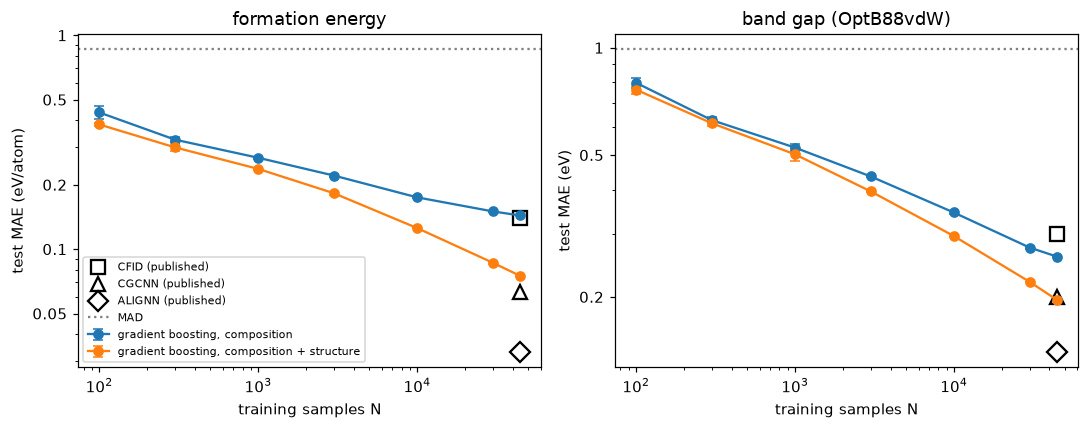

In [8]:
tr0, va0, te0 = splits[0]
sizes = [100, 300, 1000, 3000, 10000, 30000, len(tr0)]
rng = np.random.default_rng(0)
curves = {}
for t in TARGETS:
    for feat in X:
        rows = []
        for n in sizes:
            draws = [tr0] if n == len(tr0) else [rng.choice(tr0, n, replace=False) for _ in range(3)]
            scores = []
            for sub in draws:
                model = hgb()
                model.fit(X[feat][sub], y[t][sub], X_val=X[feat][va0], y_val=y[t][va0])
                scores.append(mae(model.predict(X[feat][te0]), y[t][te0]))
            rows.append(scores)
        curves[(t, feat)] = rows

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (t, (_, label, unit)) in zip(axes, TARGETS.items(), strict=True):
    for feat, color in zip(X, ("C0", "C1"), strict=True):
        means = np.array([np.mean(r) for r in curves[(t, feat)]])
        sds = np.array([np.std(r) for r in curves[(t, feat)]])
        ax.errorbar(sizes, means, yerr=sds, marker="o", color=color, capsize=3, label=f"gradient boosting, {feat}")
        big = np.array(sizes) >= 1000
        slope = np.polyfit(np.log(np.array(sizes)[big]), np.log(means[big]), 1)[0]
        print(f"{label}, {feat}: slope for N >= 1000 = {slope:.2f}")
    for model_name, marker in (("CFID", "s"), ("CGCNN", "^"), ("ALIGNN", "D")):
        ax.plot(PAPER_N_TRAIN, float(PAPER[t][model_name]), marker=marker, markersize=9, markerfacecolor="none",
                markeredgecolor="k", markeredgewidth=1.5, linestyle="none", label=f"{model_name} (published)")
    ax.axhline(float(PAPER[t]["MAD"]), color="gray", linestyle=":", label="MAD")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("training samples N")
    ax.set_ylabel(f"test MAE ({unit})")
    ax.set_title(label)
axes[0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig("figures/learning_curves.png")
plt.show()

## 7. Parity plots

Predicted against DFT values for the test set of split 0, gradient boosting with composition and structure features. The color is the number of materials per bin, on a log scale.

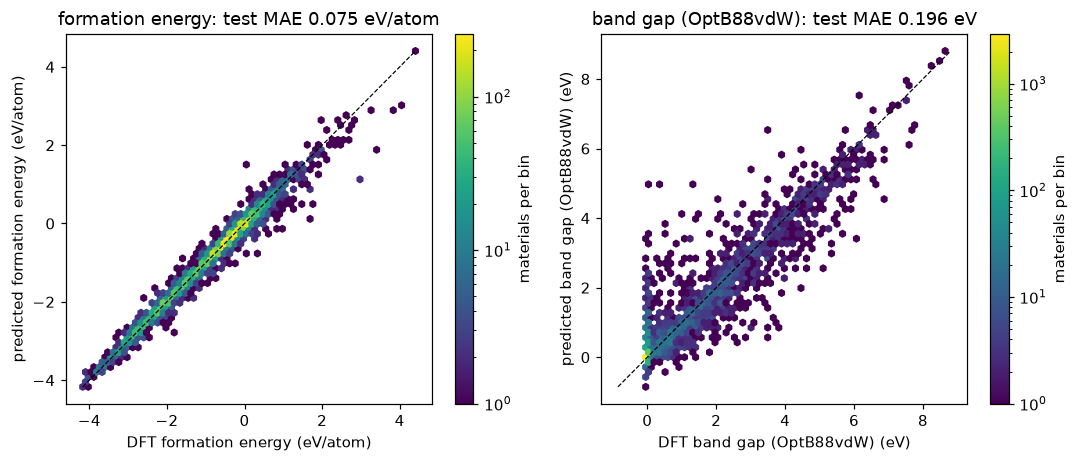

band gap: metals (gap = 0) in the test set 67.8%; their mean predicted gap 0.068 eV; predictions below 0: 1573 of 5571
band gap test MAE 0.196 eV as predicted, 0.187 eV with negative predictions set to 0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, (t, (_, label, unit)) in zip(axes, TARGETS.items(), strict=True):
    truth, pred = y[t][te0], best_pred[t]
    lo, hi = min(truth.min(), pred.min()), max(truth.max(), pred.max())
    hb = ax.hexbin(truth, pred, gridsize=60, norm=LogNorm(), cmap="viridis", mincnt=1, extent=(lo, hi, lo, hi))
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
    ax.set_xlabel(f"DFT {label} ({unit})")
    ax.set_ylabel(f"predicted {label} ({unit})")
    ax.set_title(f"{label}: test MAE {mae(pred, truth):.3f} {unit}")
    fig.colorbar(hb, ax=ax, label="materials per bin")
fig.tight_layout()
fig.savefig("figures/parity.png")
plt.show()
pred_eg = best_pred["Eg"]
metal = y["Eg"][te0] == 0
print(f"band gap: metals (gap = 0) in the test set {metal.mean():.1%}; their mean predicted gap {pred_eg[metal].mean():.3f} eV; "
      f"predictions below 0: {(pred_eg < 0).sum()} of {len(pred_eg)}")
print(f"band gap test MAE {mae(pred_eg, y['Eg'][te0]):.3f} eV as predicted, "
      f"{mae(np.clip(pred_eg, 0, None), y['Eg'][te0]):.3f} eV with negative predictions set to 0")

## 8. What the model uses

Permutation importance: shuffle one feature across the test set and measure how much the test MAE grows (five shuffles per feature). It is measured on held-out data, unlike the split counts built into tree ensembles, which favor features with many distinct values. Correlated features share their importance: if two features carry the same information, shuffling one costs little because the other remains. The importance of whole blocks (all composition or all structure features shuffled together) avoids that problem.

test MAE 0.0750 eV/atom; increase when a whole block is shuffled (mean of 5):


  composition (136)  +1.021 eV/atom


  structure (14)     +0.444 eV/atom


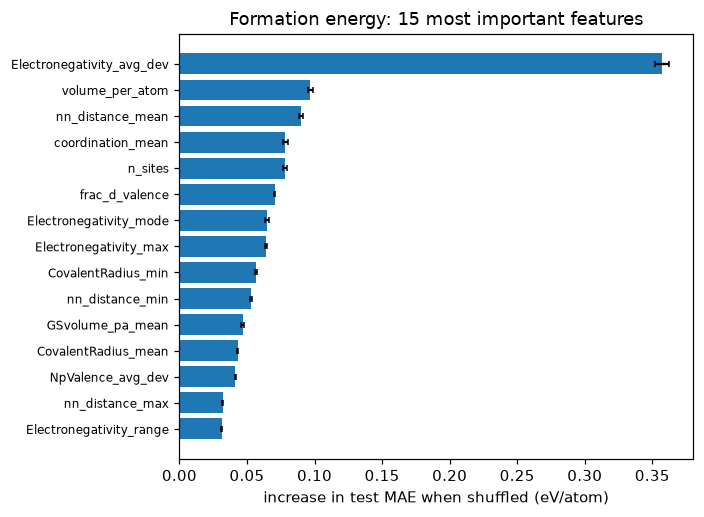

In [10]:
t = "Ef"
model = best_fit[t]
features = X["composition + structure"][te0]
truth = y[t][te0]
names = names_c + names_s
pi = permutation_importance(model, features, truth, scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
order = np.argsort(pi.importances_mean)[::-1][:15]

base = mae(model.predict(features), truth)
blocks = {"composition (136)": np.arange(len(names_c)), "structure (14)": np.arange(len(names_c), len(names))}
print(f"test MAE {base:.4f} eV/atom; increase when a whole block is shuffled (mean of 5):")
for block, cols in blocks.items():
    rises = []
    for _ in range(5):
        shuffled = features.copy()
        shuffled[:, cols] = features[rng.permutation(len(features))][:, cols]
        rises.append(mae(model.predict(shuffled), truth) - base)
    print(f"  {block:18s} +{np.mean(rises):.3f} eV/atom")

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.barh(range(len(order))[::-1], pi.importances_mean[order], xerr=pi.importances_std[order], color="C0", capsize=2)
ax.set_yticks(range(len(order))[::-1])
ax.set_yticklabels([names[i] for i in order], fontsize=8)
ax.set_xlabel("increase in test MAE when shuffled (eV/atom)")
ax.set_title("Formation energy: 15 most important features")
fig.tight_layout()
fig.savefig("figures/permutation_importance.png")
plt.show()

## Summary

In [11]:
w = max(len(row[0]) for row in summary)
print(f"{'quantity':{w}s}  {'this run':>16s}  {'check':>22s}  check from")
for q, this, check, source in summary:
    print(f"{q:{w}s}  {this:>16s}  {check:>22s}  {source}")

quantity                                                                        this run                   check  check from
MAD of formation energy (eV/atom)                                                  0.861                    0.86  Choudhary & DeCost 2021
MAD of band gap (OptB88vdW) (eV)                                                   0.993                    0.99  Choudhary & DeCost 2021
element data, Number = Z                                                           89/89                   89/89  pymatgen
element data, AtomicWeight = atomic mass                                           89/89                   89/89  pymatgen
element data, Row = period                                                         89/89                   89/89  pymatgen
element data, Column = group                                                       89/89                   89/89  pymatgen
element data, NsValence                                                            89/89                   

## Discussion

- **The pipeline reproduces the published baseline.** With the CFID descriptors, the same split, training and metric code gives 0.135 eV/atom and 0.288 eV, against 0.14 and 0.30 in the paper, and the MADs of the targets agree to the printed digits. The split is not theirs, so agreement to within about 0.01 is what can be expected.
- **150 simple features beat 1557 CFID features.** Gradient boosting on Magpie-style composition statistics plus 14 structure features reaches 0.076 ± 0.002 eV/atom for the formation energy: about half the CFID error and 1.2 times the published CGCNN error (0.063); ALIGNN (0.033) is 2.3 times better. For the band gap, 0.198 ± 0.002 eV equals the published CGCNN value (0.20). A graph network has to beat these numbers, not the MAD, to show that learning from the structure directly is worth its cost.
- **Composition is not enough.** With composition alone the formation-energy error is 0.144 eV/atom and its learning curve flattens (slope −0.17 above 1000 samples): materials with the same formula and different structures (polymorphs) cannot be told apart, which sets a floor that more data does not remove. Fourteen structure features halve the error and keep the curve falling (slope −0.31). Neither curve has saturated at the full training set.
- **Ionicity first.** The most important single feature for the formation energy is the spread of electronegativity in the compound. Pauling defined electronegativity through the extra stability of a bond between unlike atoms, which grows as (χ_A − χ_B)², so a formation-energy model that leans on this feature is reassuring. Correlated features share their importance, so the ranking below the top is not reliable feature by feature; the block test is: shuffling all composition features costs 1.02 eV/atom, all structure features 0.44 eV/atom.
- **The band gap is two problems.** Two thirds of the materials are metals with a gap of exactly 0, so the overall MAE flatters the model: for the materials that have a gap it is 0.419 eV, twice as large. The regressor also predicts negative gaps for 1573 of the 5571 test materials; setting those to 0 changes the MAE from 0.196 eV to 0.187 eV. A metal/non-metal classifier followed by a regressor for the gap is the natural next step.
- **What these numbers do not say.** Every split here is random, so nearly every test material has close relatives (same elements, same structure type) in the training set, and the errors measure interpolation. How much they grow for chemistry the model has not seen is the subject of the `data_splits` experiment.